## Copyright 2022 Google LLC. Double-click for license information.

In [ ]:
# Copyright 2022 Google LLC
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#      http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

## Prompt-to-Prompt with Stable Diffusion

In [ ]:
from typing import Optional, Union, Tuple, List, Callable, Dict
import torch
from diffusers import StableDiffusionPipeline
import torch.nn.functional as nnf
import numpy as np
import abc
import ptp_utils
import seq_aligner

For loading the Stable Diffusion using Diffusers, follow the instuctions https://huggingface.co/blog/stable_diffusion and update ```MY_TOKEN``` with your token.
Set ```LOW_RESOURCE``` to ```True``` for running on 12GB GPU.

In [ ]:
MY_TOKEN = '<replace with your token>'
LOW_RESOURCE = False
NUM_DIFFUSION_STEPS = 50
GUIDANCE_SCALE = 7.5
MAX_NUM_WORDS = 77
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
ldm_stable = StableDiffusionPipeline.from_pretrained("CompVis/stable-diffusion-v1-4", use_auth_token=MY_TOKEN).to(device)
tokenizer = ldm_stable.tokenizer

Keyword arguments {'use_auth_token': '<replace with your token>'} are not expected by StableDiffusionPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## Prompt-to-Prompt Attnetion Controllers
Our main logic is implemented in the `forward` call in an `AttentionControl` object.
The forward is called in each attention layer of the diffusion model and it can modify the input attnetion weights `attn`.

`is_cross`, `place_in_unet in ("down", "mid", "up")`, `AttentionControl.cur_step` help us track the exact attention layer and timestamp during the diffusion iference.


In [ ]:
class LocalBlend:

    def __call__(self, x_t, attention_store):
        k = 1
        maps = attention_store["down_cross"][2:4] + attention_store["up_cross"][:3]
        maps = [item.reshape(self.alpha_layers.shape[0], -1, 1, 16, 16, MAX_NUM_WORDS) for item in maps]
        maps = torch.cat(maps, dim=1)
        maps = (maps * self.alpha_layers).sum(-1).mean(1)
        mask = nnf.max_pool2d(maps, (k * 2 + 1, k * 2 +1), (1, 1), padding=(k, k))
        mask = nnf.interpolate(mask, size=(x_t.shape[2:]))
        mask = mask / mask.max(2, keepdims=True)[0].max(3, keepdims=True)[0]
        mask = mask.gt(self.threshold)
        mask = (mask[:1] + mask[1:]).float()
        x_t = x_t[:1] + mask * (x_t - x_t[:1])
        return x_t

    def __init__(self, prompts: List[str], words: [List[List[str]]], threshold=.3):
        alpha_layers = torch.zeros(len(prompts),  1, 1, 1, 1, MAX_NUM_WORDS)
        for i, (prompt, words_) in enumerate(zip(prompts, words)):
            if type(words_) is str:
                words_ = [words_]
            for word in words_:
                ind = ptp_utils.get_word_inds(prompt, word, tokenizer)
                alpha_layers[i, :, :, :, :, ind] = 1
        self.alpha_layers = alpha_layers.to(device)
        self.threshold = threshold


class AttentionControl(abc.ABC):

    def step_callback(self, x_t):
        return x_t

    def between_steps(self):
        return

    @property
    def num_uncond_att_layers(self):
        return self.num_att_layers if LOW_RESOURCE else 0

    @abc.abstractmethod
    def forward (self, attn, is_cross: bool, place_in_unet: str):
        raise NotImplementedError

    def __call__(self, attn, is_cross: bool, place_in_unet: str):
        if self.cur_att_layer >= self.num_uncond_att_layers:
            if LOW_RESOURCE:
                attn = self.forward(attn, is_cross, place_in_unet)
            else:
                h = attn.shape[0]
                attn[h // 2:] = self.forward(attn[h // 2:], is_cross, place_in_unet)
        self.cur_att_layer += 1
        if self.cur_att_layer == self.num_att_layers + self.num_uncond_att_layers:
            self.cur_att_layer = 0
            self.cur_step += 1
            self.between_steps()
        return attn

    def reset(self):
        self.cur_step = 0
        self.cur_att_layer = 0

    def __init__(self):
        self.cur_step = 0
        self.num_att_layers = -1
        self.cur_att_layer = 0

class EmptyControl(AttentionControl):

    def forward (self, attn, is_cross: bool, place_in_unet: str):
        return attn


class AttentionStore(AttentionControl):

    @staticmethod
    def get_empty_store():
        return {"down_cross": [], "mid_cross": [], "up_cross": [],
                "down_self": [],  "mid_self": [],  "up_self": []}

    def forward(self, attn, is_cross: bool, place_in_unet: str):
        key = f"{place_in_unet}_{'cross' if is_cross else 'self'}"
        if attn.shape[1] <= 32 ** 2:  # avoid memory overhead
            self.step_store[key].append(attn)
        return attn

    def between_steps(self):
        if len(self.attention_store) == 0:
            self.attention_store = self.step_store
        else:
            for key in self.attention_store:
                for i in range(len(self.attention_store[key])):
                    self.attention_store[key][i] += self.step_store[key][i]
        self.step_store = self.get_empty_store()

    def get_average_attention(self):
        average_attention = {key: [item / self.cur_step for item in self.attention_store[key]] for key in self.attention_store}
        return average_attention


    def reset(self):
        super(AttentionStore, self).reset()
        self.step_store = self.get_empty_store()
        self.attention_store = {}

    def __init__(self):
        super(AttentionStore, self).__init__()
        self.step_store = self.get_empty_store()
        self.attention_store = {}


class AttentionControlEdit(AttentionStore, abc.ABC):

    def step_callback(self, x_t):
        if self.local_blend is not None:
            x_t = self.local_blend(x_t, self.attention_store)
        return x_t

    def replace_self_attention(self, attn_base, att_replace):
        if att_replace.shape[2] <= 16 ** 2:
            return attn_base.unsqueeze(0).expand(att_replace.shape[0], *attn_base.shape)
        else:
            return att_replace

    @abc.abstractmethod
    def replace_cross_attention(self, attn_base, att_replace):
        raise NotImplementedError

    def forward(self, attn, is_cross: bool, place_in_unet: str):
        super(AttentionControlEdit, self).forward(attn, is_cross, place_in_unet)
        if is_cross or (self.num_self_replace[0] <= self.cur_step < self.num_self_replace[1]):
            h = attn.shape[0] // (self.batch_size)
            attn = attn.reshape(self.batch_size, h, *attn.shape[1:])
            attn_base, attn_repalce = attn[0], attn[1:]
            if is_cross:
                alpha_words = self.cross_replace_alpha[self.cur_step]
                attn_repalce_new = self.replace_cross_attention(attn_base, attn_repalce) * alpha_words + (1 - alpha_words) * attn_repalce
                attn[1:] = attn_repalce_new
            else:
                attn[1:] = self.replace_self_attention(attn_base, attn_repalce)
            attn = attn.reshape(self.batch_size * h, *attn.shape[2:])
        return attn

    def __init__(self, prompts, num_steps: int,
                 cross_replace_steps: Union[float, Tuple[float, float], Dict[str, Tuple[float, float]]],
                 self_replace_steps: Union[float, Tuple[float, float]],
                 local_blend: Optional[LocalBlend]):
        super(AttentionControlEdit, self).__init__()
        self.batch_size = len(prompts)
        self.cross_replace_alpha = ptp_utils.get_time_words_attention_alpha(prompts, num_steps, cross_replace_steps, tokenizer).to(device)
        if type(self_replace_steps) is float:
            self_replace_steps = 0, self_replace_steps
        self.num_self_replace = int(num_steps * self_replace_steps[0]), int(num_steps * self_replace_steps[1])
        self.local_blend = local_blend

class AttentionReplace(AttentionControlEdit):

    def replace_cross_attention(self, attn_base, att_replace):
        return torch.einsum('hpw,bwn->bhpn', attn_base, self.mapper)

    def __init__(self, prompts, num_steps: int, cross_replace_steps: float, self_replace_steps: float,
                 local_blend: Optional[LocalBlend] = None):
        super(AttentionReplace, self).__init__(prompts, num_steps, cross_replace_steps, self_replace_steps, local_blend)
        self.mapper = seq_aligner.get_replacement_mapper(prompts, tokenizer).to(device)


class AttentionRefine(AttentionControlEdit):

    def replace_cross_attention(self, attn_base, att_replace):
        attn_base_replace = attn_base[:, :, self.mapper].permute(2, 0, 1, 3)
        attn_replace = attn_base_replace * self.alphas + att_replace * (1 - self.alphas)
        return attn_replace

    def __init__(self, prompts, num_steps: int, cross_replace_steps: float, self_replace_steps: float,
                 local_blend: Optional[LocalBlend] = None):
        super(AttentionRefine, self).__init__(prompts, num_steps, cross_replace_steps, self_replace_steps, local_blend)
        self.mapper, alphas = seq_aligner.get_refinement_mapper(prompts, tokenizer)
        self.mapper, alphas = self.mapper.to(device), alphas.to(device)
        self.alphas = alphas.reshape(alphas.shape[0], 1, 1, alphas.shape[1])


class AttentionReweight(AttentionControlEdit):

    def replace_cross_attention(self, attn_base, att_replace):
        if self.prev_controller is not None:
            attn_base = self.prev_controller.replace_cross_attention(attn_base, att_replace)
        attn_replace = attn_base[None, :, :, :] * self.equalizer[:, None, None, :]
        return attn_replace

    def __init__(self, prompts, num_steps: int, cross_replace_steps: float, self_replace_steps: float, equalizer,
                local_blend: Optional[LocalBlend] = None, controller: Optional[AttentionControlEdit] = None):
        super(AttentionReweight, self).__init__(prompts, num_steps, cross_replace_steps, self_replace_steps, local_blend)
        self.equalizer = equalizer.to(device)
        self.prev_controller = controller


def get_equalizer(text: str, word_select: Union[int, Tuple[int, ...]], values: Union[List[float],
                  Tuple[float, ...]]):
    if type(word_select) is int or type(word_select) is str:
        word_select = (word_select,)
    equalizer = torch.ones(len(values), 77)
    values = torch.tensor(values, dtype=torch.float32)
    for word in word_select:
        inds = ptp_utils.get_word_inds(text, word, tokenizer)
        equalizer[:, inds] = values
    return equalizer


In [ ]:
from PIL import Image

def aggregate_attention(attention_store: AttentionStore, res: int, from_where: List[str], is_cross: bool, select: int):
    out = []
    attention_maps = attention_store.get_average_attention()
    num_pixels = res ** 2
    for location in from_where:
        for item in attention_maps[f"{location}_{'cross' if is_cross else 'self'}"]:
            if item.shape[1] == num_pixels:
                cross_maps = item.reshape(len(prompts), -1, res, res, item.shape[-1])[select]
                out.append(cross_maps)
    out = torch.cat(out, dim=0)
    out = out.sum(0) / out.shape[0]
    return out.cpu()


def show_cross_attention(attention_store: AttentionStore, res: int, from_where: List[str], select: int = 0):
    tokens = tokenizer.encode(prompts[select])
    decoder = tokenizer.decode
    attention_maps = aggregate_attention(attention_store, res, from_where, True, select)
    images = []
    for i in range(len(tokens)):
        image = attention_maps[:, :, i]
        image = 255 * image / image.max()
        image = image.unsqueeze(-1).expand(*image.shape, 3)
        image = image.numpy().astype(np.uint8)
        image = np.array(Image.fromarray(image).resize((256, 256)))
        image = ptp_utils.text_under_image(image, decoder(int(tokens[i])))
        images.append(image)
    ptp_utils.view_images(np.stack(images, axis=0))


def show_self_attention_comp(attention_store: AttentionStore, res: int, from_where: List[str],
                        max_com=10, select: int = 0):
    attention_maps = aggregate_attention(attention_store, res, from_where, False, select).numpy().reshape((res ** 2, res ** 2))
    u, s, vh = np.linalg.svd(attention_maps - np.mean(attention_maps, axis=1, keepdims=True))
    images = []
    for i in range(max_com):
        image = vh[i].reshape(res, res)
        image = image - image.min()
        image = 255 * image / image.max()
        image = np.repeat(np.expand_dims(image, axis=2), 3, axis=2).astype(np.uint8)
        image = Image.fromarray(image).resize((256, 256))
        image = np.array(image)
        images.append(image)
    ptp_utils.view_images(np.concatenate(images, axis=1))

In [ ]:
def run_and_display(prompts, controller, latent=None, run_baseline=False, generator=None):
    if run_baseline:
        print("w.o. prompt-to-prompt")
        images, latent = run_and_display(prompts, EmptyControl(), latent=latent, run_baseline=False, generator=generator)
        print("with prompt-to-prompt")
    images, x_t = ptp_utils.text2image_ldm_stable(ldm_stable, prompts, controller, latent=latent, num_inference_steps=NUM_DIFFUSION_STEPS, guidance_scale=GUIDANCE_SCALE, generator=generator, low_resource=LOW_RESOURCE)
    ptp_utils.view_images(images)
    return images, x_t

## Cross-Attention Visualization
First let's generate an image and visualize the cross-attention maps for each word in the prompt.
Notice, we normalize each map to 0-1.

/content/ptp_utils.py:90: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  (1, model.unet.in_channels, height // 8, width // 8),
/content/ptp_utils.py:93: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  latents = latent.expand(batch_size,  model.unet.in_channels, height // 8, width // 8).to(model.device)


  0%|          | 0/51 [00:00<?, ?it/s]

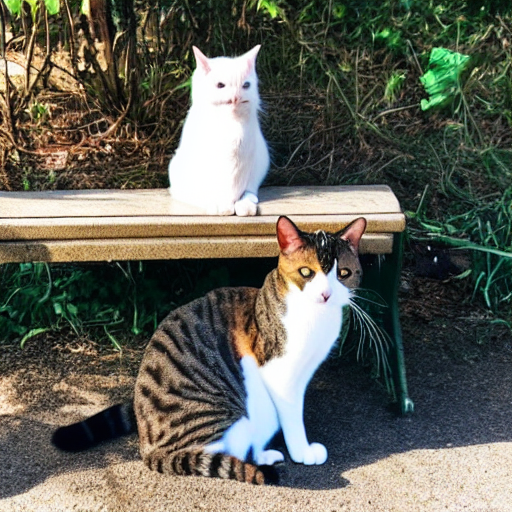

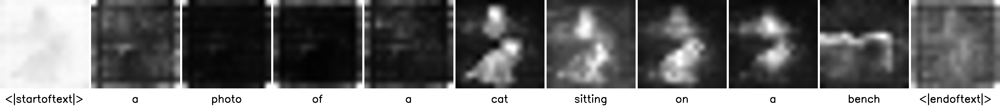

In [ ]:
g_cpu = torch.Generator().manual_seed(8888)
prompts = ["a photo of a cat sitting on a bench"]
controller = AttentionStore()
image, x_t = run_and_display(prompts, controller, latent=None, run_baseline=False, generator=g_cpu)
show_cross_attention(controller, res=16, from_where=("up", "down"))

## Replacement edit

w.o. prompt-to-prompt


  0%|          | 0/51 [00:00<?, ?it/s]

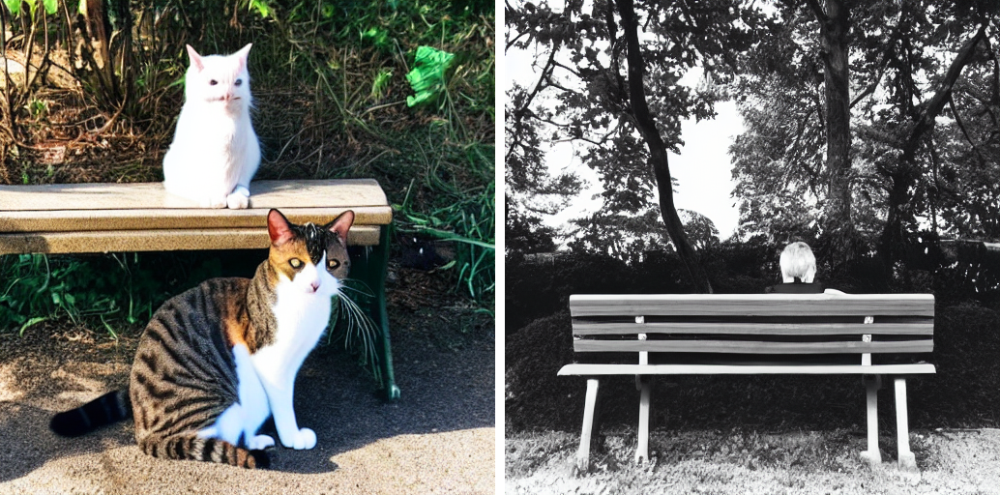

with prompt-to-prompt


  0%|          | 0/51 [00:00<?, ?it/s]

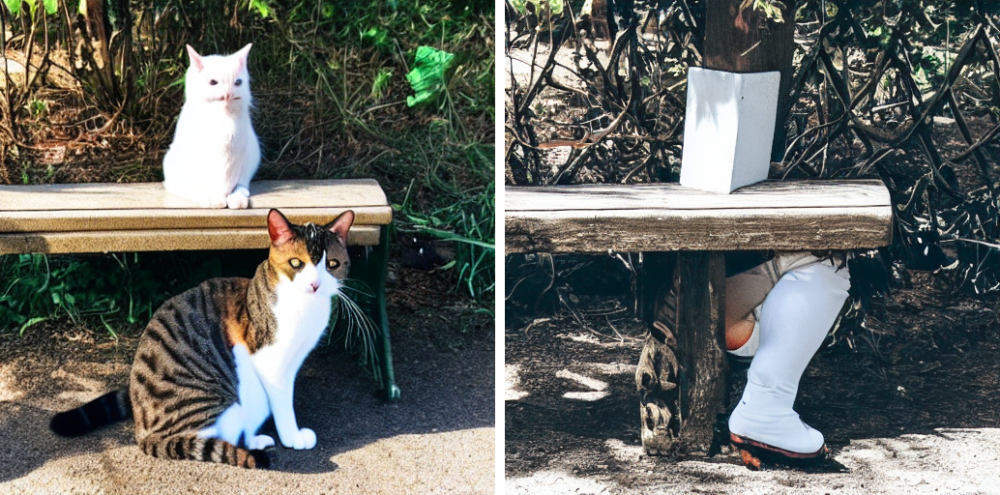

In [ ]:
prompts = ["a photo of a cat sitting on a bench",
           "a photo of a person sitting on a bench"]

controller = AttentionReplace(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.8, self_replace_steps=0.4)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=True)


w.o. prompt-to-prompt


  0%|          | 0/51 [00:00<?, ?it/s]

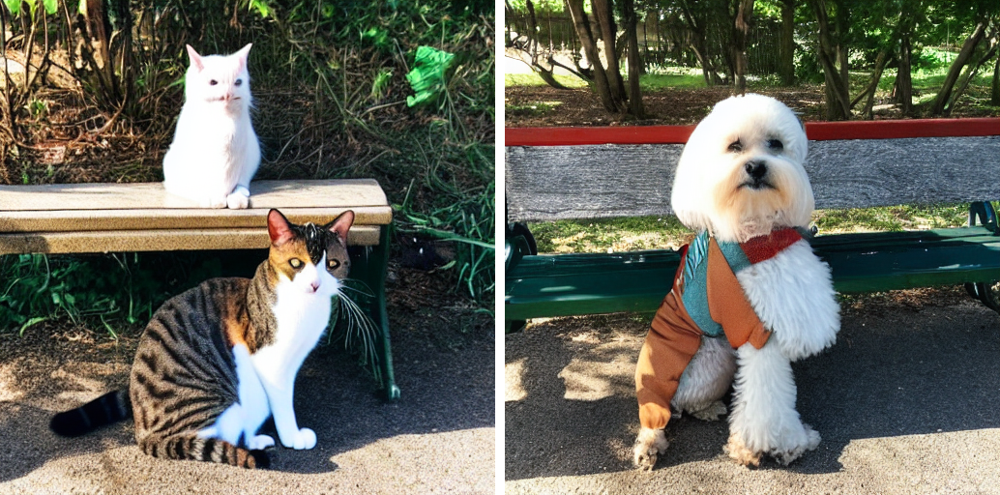

with prompt-to-prompt


  0%|          | 0/51 [00:00<?, ?it/s]

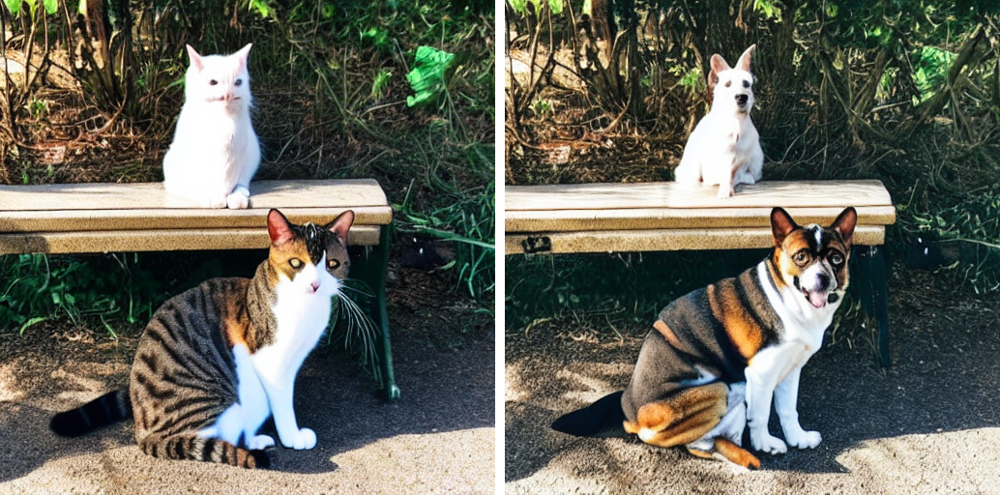

In [ ]:
prompts = ["a photo of a cat sitting on a bench",
           "a photo of a dog sitting on a bench"]

controller = AttentionReplace(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.8, self_replace_steps=0.4)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=True)

## Word swap
Cat to dog worked very well: both cats became dogs with the same pose and position, and the background was unchanged. Without Prompt-to-Prompt, the same prompt change gives a completely different image. cat to person was much harder. With strong attention injection (0.8), the cats turned into a white box and a pair of legs instead of a person.

### Modify Cross-Attention injection #steps for specific words
Next, we can reduce the restriction on our person by reducing the number of cross-attention injection with respect to the word "person".

  0%|          | 0/51 [00:00<?, ?it/s]

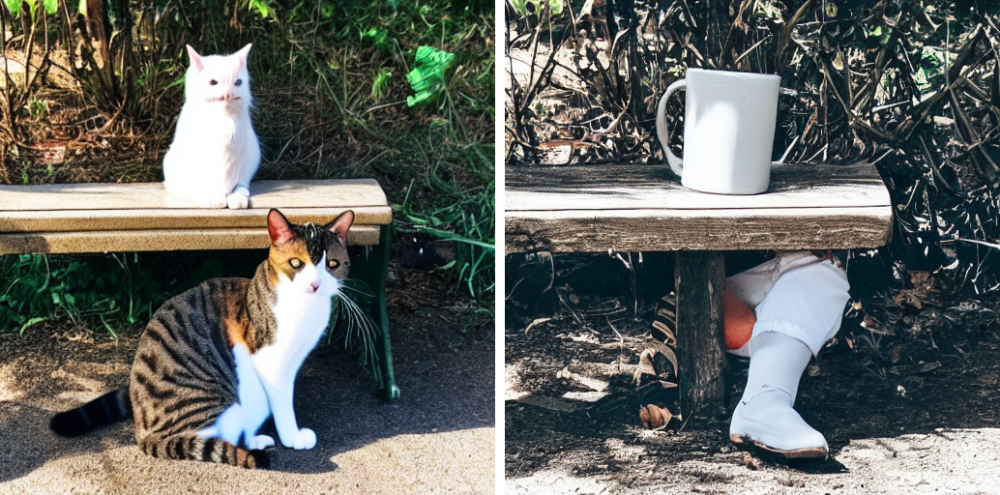

In [ ]:
prompts = ["a photo of a cat sitting on a bench",
           "a photo of a person sitting on a bench"]
controller = AttentionReplace(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps={"default_": 1., "person": .4},
                              self_replace_steps=0.4)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=False)

### Local Edit
Lastly, if we want to preseve the original background, we can apply a local edit with respect to the cats and the person.

A person only appeared after I lowered the injection for “person” and added LocalBlend.

sofa to bed changed only the furniture and kept the teddy bear identical.

  0%|          | 0/51 [00:00<?, ?it/s]

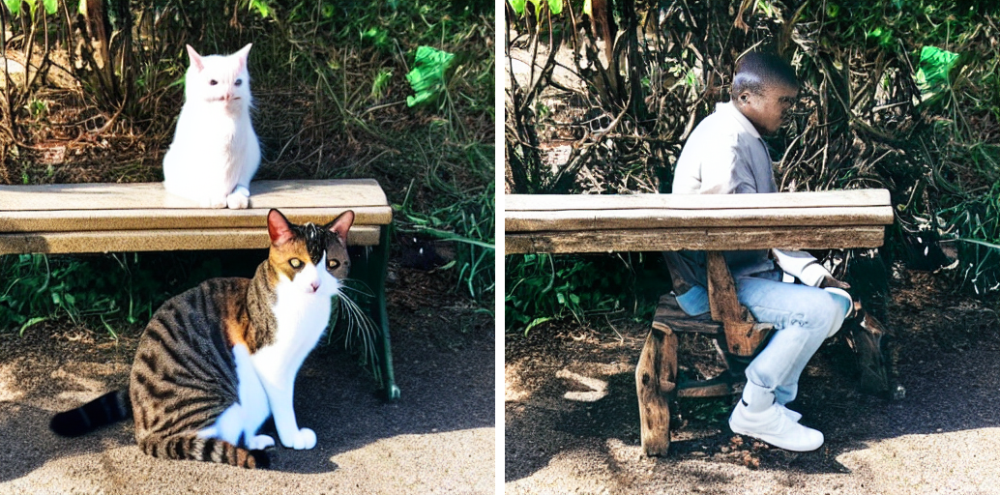

In [ ]:
prompts = ["a photo of a cat sitting on a bench",
           "a photo of a person sitting on a bench"]
lb = LocalBlend(prompts, ("cat", "person"))
controller = AttentionReplace(prompts, NUM_DIFFUSION_STEPS,
                              cross_replace_steps={"default_": 1., "person": .4},
                              self_replace_steps=0.4, local_blend=lb)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=False)

w.o. prompt-to-prompt


  0%|          | 0/51 [00:00<?, ?it/s]

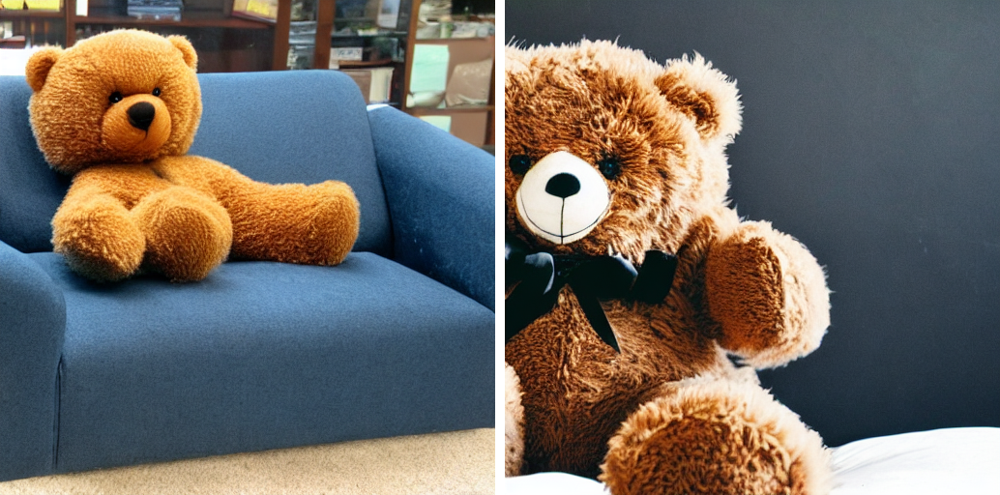

with prompt-to-prompt


  0%|          | 0/51 [00:00<?, ?it/s]

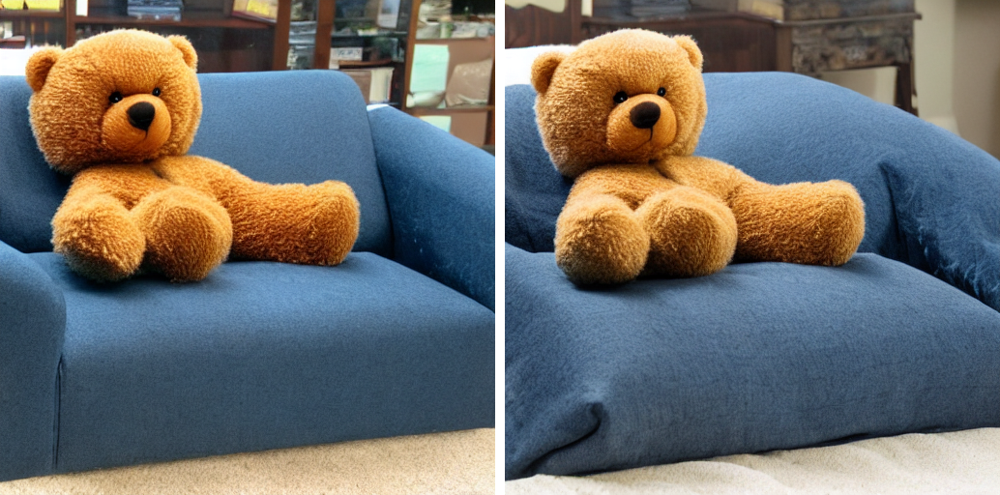

In [ ]:
prompts = ["a teddy bear sitting on a sofa",
           "a teddy bear sitting on a bed"]
lb = LocalBlend(prompts, ("sofa", "bed"))
controller = AttentionReplace(prompts, NUM_DIFFUSION_STEPS,
                              cross_replace_steps={"default_": 1., "bed": .2},
                              self_replace_steps=0.4,
                              local_blend=lb)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=True)

## Refinement edit

  0%|          | 0/51 [00:00<?, ?it/s]

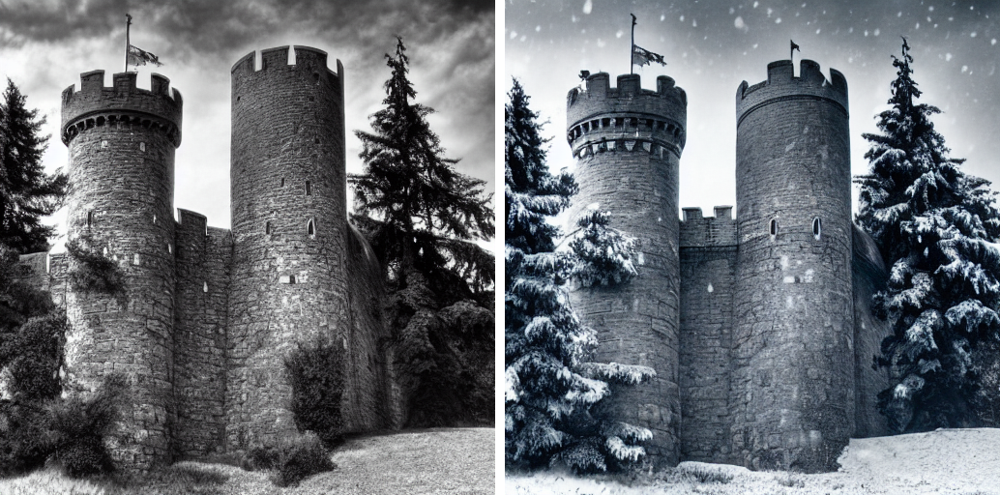

In [ ]:
prompts = ["a photo of a castle on a hill",
           "a photo of a castle on a hill in winter"]

controller = AttentionRefine(prompts, NUM_DIFFUSION_STEPS,
                             cross_replace_steps=.5,
                             self_replace_steps=.4)
_ = run_and_display(prompts, controller, latent=x_t)

  0%|          | 0/51 [00:00<?, ?it/s]

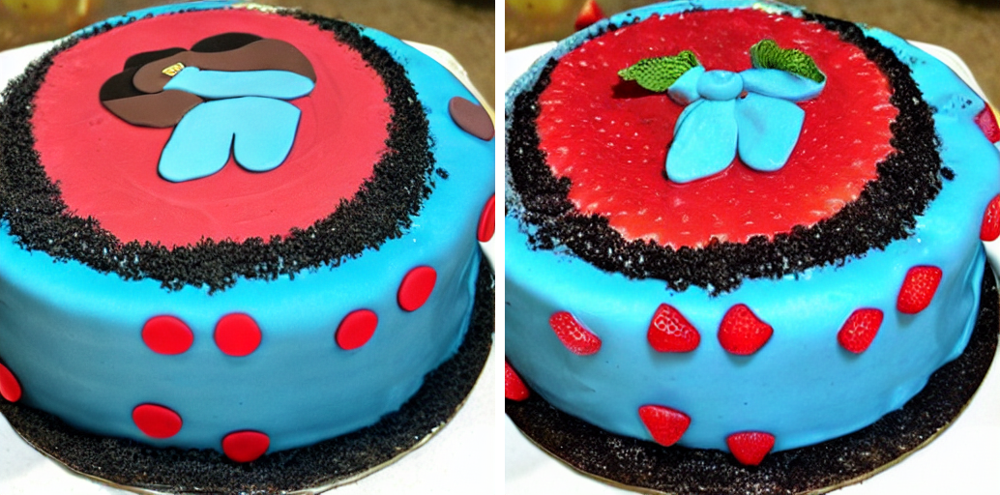

In [ ]:
prompts = ["cake",
           "strawberry cake"]

lb = LocalBlend(prompts, ("cake", "cake"))

controller = AttentionRefine(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.8,
                             self_replace_steps=.4,
                             local_blend=lb)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=False)

  0%|          | 0/51 [00:00<?, ?it/s]

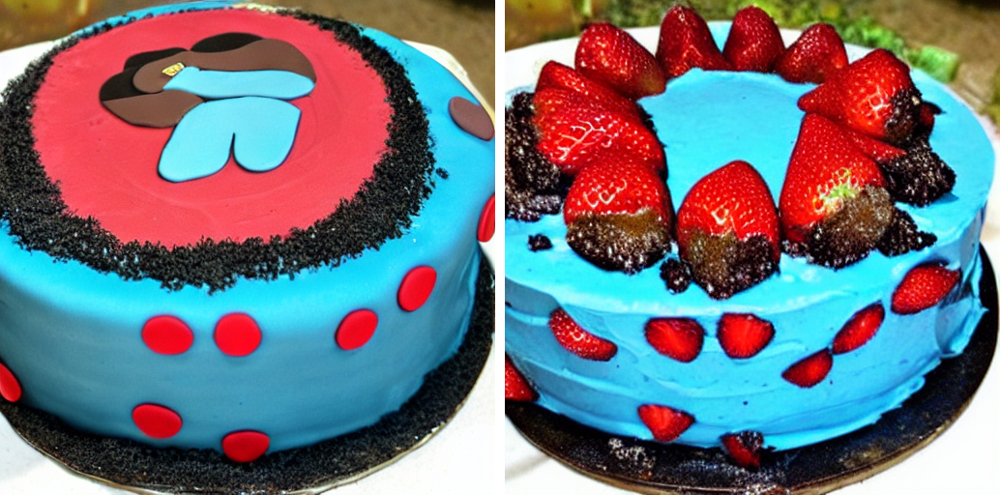

In [ ]:
prompts = ["cake",
           "strawberry cake"]

lb = LocalBlend(prompts, ("cake", "cake"))

controller = AttentionRefine(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.2,
                             self_replace_steps=.2,
                             local_blend=lb)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=False)

  0%|          | 0/51 [00:00<?, ?it/s]

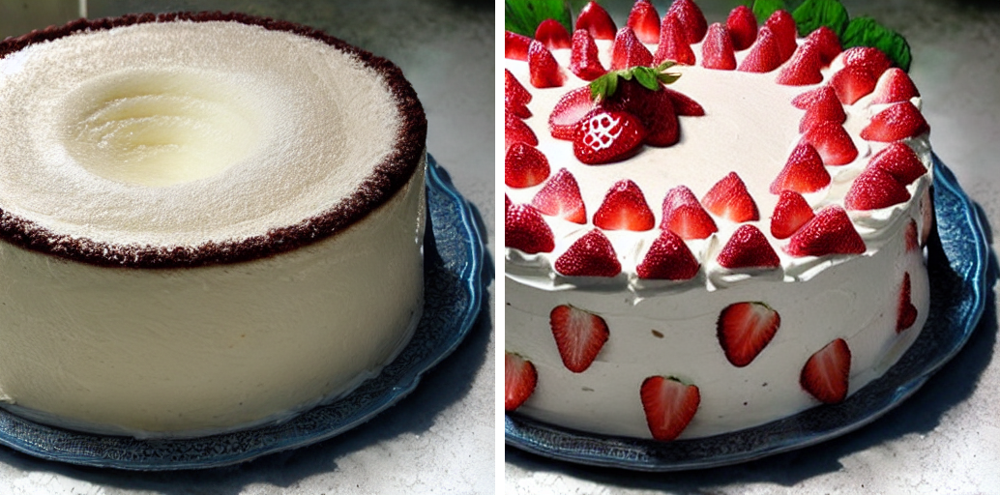

In [ ]:
prompts = ["cream cake",
           "strawberry cream cake"]

lb = LocalBlend(prompts, ("cake", "cake"))
controller = AttentionRefine(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.2,
                             self_replace_steps=.2, local_blend=lb)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=False)

Refinement. Adding “in winter” kept the castle's structure exactly and only added snow. For cream cake to strawberry cream cake, I needed low injection (0.2). With higher values in my earlier attempts, and with the plain prompt “cake”, the original cake's shape and colors were preserved too strongly, so strawberries only appeared as texture inside the old shapes.

## Attention Re-Weighting

  0%|          | 0/51 [00:00<?, ?it/s]

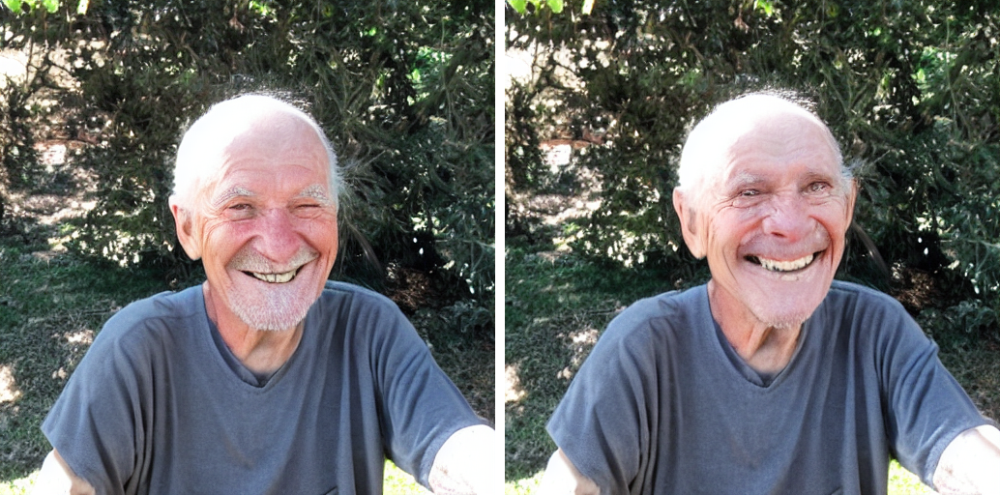

In [ ]:
prompts = ["a smiling old man"] * 2

### pay 5 times more attention to the word "smiling"
equalizer = get_equalizer(prompts[1], ("smiling",), (5,))
controller = AttentionReweight(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.8,
                               self_replace_steps=.4,
                               equalizer=equalizer)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=False)

  0%|          | 0/51 [00:00<?, ?it/s]

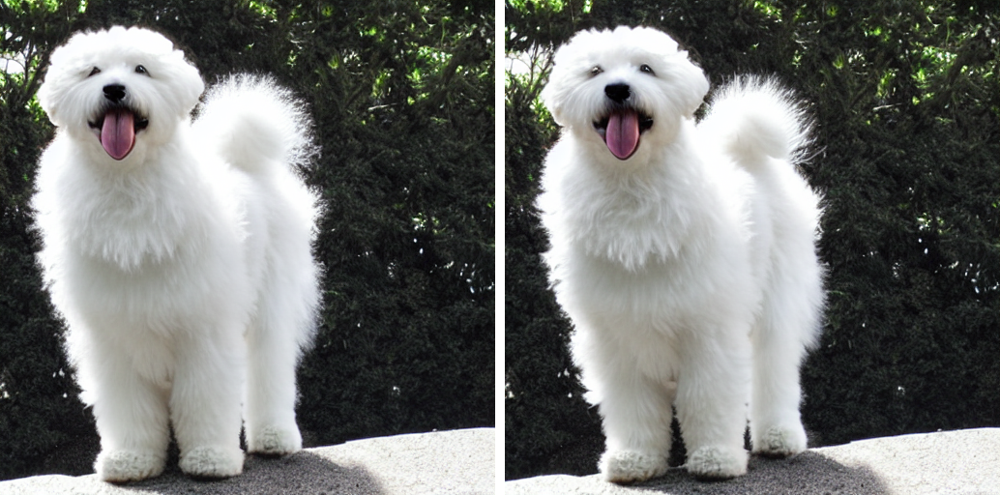

In [ ]:
prompts = ["a fluffy white dog"] * 2

### we don't wont pink bikes, only pink bear.
### we reduce the amount of pink but apply it locally on the bikes (attention re-weight + local mask )

### pay less attention to the word "fluffy"
equalizer = get_equalizer(prompts[1], ("fluffy",), (-2,))

### apply the edit on the bikes
lb = LocalBlend(prompts, ("dog", "dog"))
controller = AttentionReweight(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.8,
                               self_replace_steps=.4,
                               equalizer=equalizer,
                               local_blend=lb)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=False)

  0%|          | 0/51 [00:00<?, ?it/s]

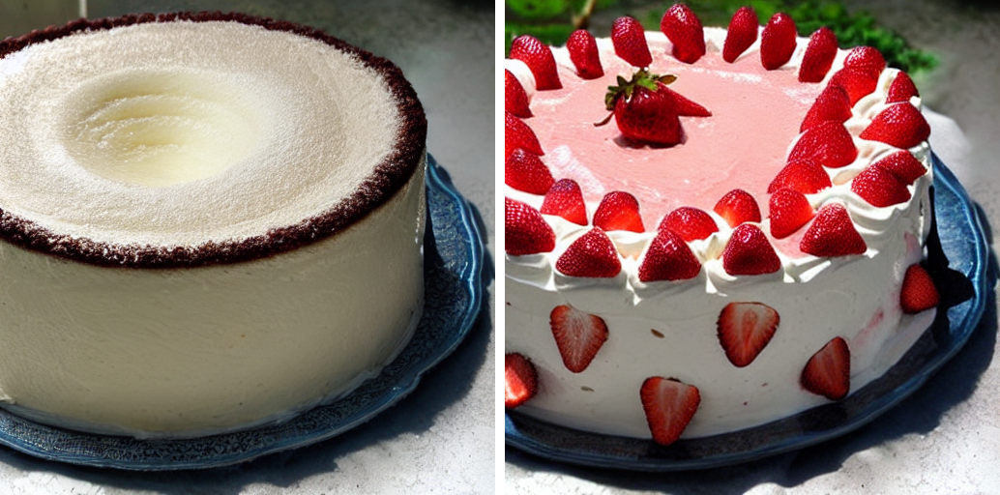

In [ ]:
prompts = ["cream cake",
           "strawberry cream cake"]

lb = LocalBlend(prompts, ("cake", "cake"))
controller_a = AttentionRefine(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.4,
                               self_replace_steps=.4, local_blend=lb)

### pay 5 times more attention to the word "strawberry"
equalizer = get_equalizer(prompts[1], ("strawberry",), (5,))
controller = AttentionReweight(prompts, NUM_DIFFUSION_STEPS, cross_replace_steps=.2,
                               self_replace_steps=.2, equalizer=equalizer, local_blend=lb,
                               controller=controller_a)
_ = run_and_display(prompts, controller, latent=x_t, run_baseline=False)

## Re-weighting.
Increasing “smiling” made the man smile more widely, and increasing “strawberry” made the cake pinker with more strawberries. Decreasing “fluffy” had almost no effect, since the dog's appearance is already implied by “white dog” and its breed.

## What surprised me.
Changing a single word while keeping $x_T$ and the attention maps fixed is enough to edit only the target object and leave everything else almost unchanged, without any training. The cross-attention maps are also very interpretable: each word attends to the exact region of its object, which is what makes local editing possible. Global edits such as season, color and texture changes look especially natural.

## What is lacking.
The edit is constrained by the original layout. The new object has to fit the shape of the old one, so large changes (cat → person) fail unless the injection is weakened. Results also depend heavily on hand-tuned hyperparameters (cross_replace_steps, self_replace_steps, the re-weighting value), and these need to be tuned for each image. Re-weighting works for some words but not others. Finally, the method only applies to generated images; editing real photos requires an extra, slow inversion step.